# Task 2: Coordinate Transformations

In this notebook we use what we have learned about marker detection in the last notebook. The goal is to explain how we can transform the positions of detected Aruco markers from the camera coordinate frame into a robot-specific reference frame, and finally into a world coordinate frame.

We will do this using two different conventions for the rotations involved: **intrinsic rotations** and **extrinsic rotations**. The two conventions give different results whenever more than one rotation axis is involved (which is the case for our camera), so it is important to be consistent about which one we use.

## Imports

In [50]:
# imports
import cv2
from matplotlib import pyplot as plt
import numpy as np
import yaml
import io

## Setup

We again load the camera parameters. This time we not only need them for preprocessing our image, but we will also use them when estimating where the markers are relative to the camera.

In [51]:
# load camera parameters
with open("../notebooks/camera_intrinsics.yml", 'r') as stream:
    camera_intrinsics = yaml.safe_load(stream)
camera_matrix = np.array(camera_intrinsics["camera_matrix"]["data"]).reshape((3,3))
distortion_coefficients = np.array(camera_intrinsics["distortion_coefficients"]["data"])

print("camera matrix:\n", camera_matrix)
print("distortion coefficients:", distortion_coefficients)

camera matrix:
 [[635.93    0.    444.27 ]
 [  0.    634.263 256.835]
 [  0.      0.      1.   ]]
distortion coefficients: [-0.372403    0.157163   -0.00424357 -0.00231644 -0.0522724 ]


The other component for estimating the markers' poses and positions we need to know beforehand is the size of our markers.

In [52]:
# set marker size (in meters)
marker_size = 0.05

## Detect Aruco Markers

**Task:** Use the *cv2.aruco.DICT_ARUCO_ORIGINAL* dictionary for detecting the markers in the given image.

**Note:** In this specific case we do **not** have to undistort the image before detecting the markers. Undistortion is handled internally inside *solvePnP* (which we will use in the next task). So we simply detect the markers in the raw image and let the pose estimation take care of the distortions.

**Note:** The list that contains the marker ids should be named *ids*, in order for the provided code to run without changes.

Detected marker ids: [548 863 860 650]


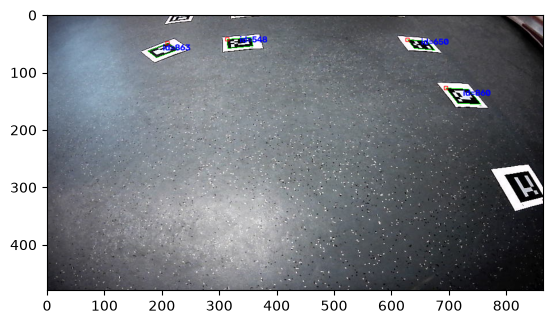

In [53]:
# load image
img = cv2.imread("../notebooks/2024-09-12_17-29-34/img_282.jpg")

### Your code here ###
# setup the aruco detector with the requested dictionary
dictionary = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_ARUCO_ORIGINAL)
detector = cv2.aruco.ArucoDetector(dictionary)

# detect markers in the image
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
corners, ids, rejected = detector.detectMarkers(gray)

# draw the detected markers onto the image

img_with_markers= img.copy()
cv2.aruco.drawDetectedMarkers(img_with_markers, corners, ids)
###

print("Detected marker ids:", ids.ravel() if ids is not None else None)
# convert BGR -> RGB for correct colours in matplotlib
plt.figure()
plt.imshow(cv2.cvtColor(img_with_markers, cv2.COLOR_BGR2RGB))
plt.show()

## Pose Estimation

**Task:** Use OpenCV's *solvePnP* function to estimate the poses of the markers detected in the previous task.

**Note:** The function should get the camera matrix and distortion parameters as arguments, because it internally handles the *undistortion* step that we did separately in the last notebook.

In [54]:
# estimate marker poses using the detected marker corners from the image,
# the camera parameters, and the (known) size of the marker
marker_rvecs = []
marker_tvecs = []

# 3D coordinates of the four marker corners in the marker's own coordinate frame (meters)
marker_points = np.array([[-marker_size / 2, marker_size / 2, 0],
                          [marker_size / 2, marker_size / 2, 0],
                          [marker_size / 2, -marker_size / 2, 0],
                          [-marker_size / 2, -marker_size / 2, 0]])

### Your code here ###
# for each detected marker, use solvePnP to estimate its pose and
# append the resulting rotation and translation vectors
for marker_corners in corners:
    image_points = marker_corners.reshape(4, 2)
    ok, rvec, tvec = cv2.solvePnP(
        marker_points,
        image_points,
        camera_matrix,
        distortion_coefficients,
        flags=cv2.SOLVEPNP_IPPE_SQUARE
    )
    if ok:
        marker_rvecs.append(rvec)
        marker_tvecs.append(tvec)
###

print(f"Estimated poses for {len(marker_rvecs)} markers")

Estimated poses for 4 markers


**Task:** Use OpenCV's *drawFrameAxes* function to visualise the estimated marker poses.

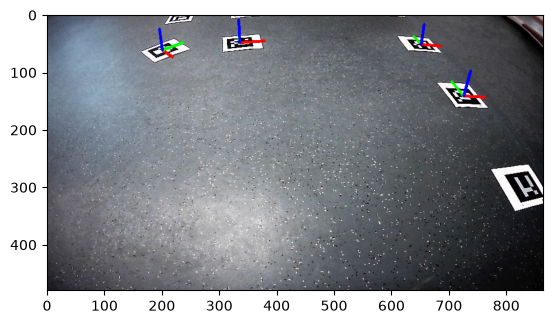

In [55]:
# visualise the estimated marker poses in the image
img_axis = img.copy()
axis_length = marker_size  # length of the drawn axes in meters

### Your code here ###
# draw the coordinate frame axes for each marker using cv2.drawFrameAxes

for i in range(len(ids)):
    cv2.drawFrameAxes(
        img_axis,
        camera_matrix,
        distortion_coefficients,
        marker_rvecs[i],
        marker_tvecs[i],
        marker_size
    )
###

plt.figure()
plt.imshow(cv2.cvtColor(img_axis, cv2.COLOR_BGR2RGB))
plt.show()

## Projecting Aruco Marker Positions to Robot and World Frame

Before we can project the marker poses into the robot frame, we need a few helper functions. A 3D pose (rotation + translation) can be represented as a 4x4 homogeneous transformation matrix:

```
    T = | R  t |
        | 0  1 |
```

where ``R`` is the 3x3 rotation matrix and ``t`` the translation vector. We need two helpers: one that builds a transformation matrix from a rotation- and translation-vector pair, and one that does the reverse.

The rotation is described by three angles (x, y, z) and the order in which they are applied matters. By default this notebook uses **intrinsic** rotations, i.e. we rotate about the *body* (moving) axes in the order z -> y -> x. This is equivalent to the matrix product ``R = Rz(alpha) * Ry(beta) * Rx(gamma)``.

In [56]:
def rotation_matrix(x_rotation, y_rotation, z_rotation):
    """Rotation matrix for an INTRINSIC z-y-x rotation.

    Rotates about the body axes in the order z, then y, then x, which is
    equivalent to R = Rz(alpha) * Ry(beta) * Rx(gamma).
    Here alpha = z_rotation, beta = y_rotation, gamma = x_rotation.
    """
    alpha = z_rotation
    beta = y_rotation
    gamma = x_rotation

    # https://en.wikipedia.org/wiki/Rotation_matrix
    return np.array([
        [np.cos(alpha)*np.cos(beta), np.cos(alpha)*np.sin(beta)*np.sin(gamma)-np.sin(alpha)*np.cos(gamma), np.cos(alpha)*np.sin(beta)*np.cos(gamma)+np.sin(alpha)*np.sin(gamma)],
        [np.sin(alpha)*np.cos(beta), np.sin(alpha)*np.sin(beta)*np.sin(gamma)+np.cos(alpha)*np.cos(gamma), np.sin(alpha)*np.sin(beta)*np.cos(gamma)-np.cos(alpha)*np.sin(gamma)],
        [-np.sin(beta), np.cos(beta)*np.sin(gamma), np.cos(beta)*np.cos(gamma)]
    ])

**Task:** Implement ``vectors_to_transformation_matrix`` which turns a rotation vector (x, y, z angles) and a translation vector into a 4x4 transformation matrix.

In [57]:
def vectors_to_transformation_matrix(rotation, translation):
    ### Your code here ###
    # build the rotation matrix from the rotation vector (x, y, z)
    x,y,z=rotation
    R_matrix=rotation_matrix(x,y,z)

    # create a 4x4 identity matrix and fill in the rotation and translation
    T = np.eye(4)
    T[:3, :3] = R_matrix
    T[:3, 3] = translation
    ###
    return T

**Task:** Implement the inverse helper ``transformation_matrix_to_vectors`` which extracts the (x, y, z) rotation vector and the translation vector from a 4x4 transformation matrix.

In [ ]:
def transformation_matrix_to_vectors(t):
    ### Your code here ###
    # extract the rotation matrix and translation vector
    R = t[:3, :3]
    translation = t[:3, 3]
    # recover the z-y-x intrinsic euler angles from the rotation matrix
    x_rotation = np.arctan2(R[2, 1], R[2, 2])
    y_rotation = np.arctan2(-R[2, 0], np.sqrt(R[0, 0]**2 + R[1, 0]**2))
    z_rotation = np.arctan2(R[1, 0], R[0, 0])
    ###
    return np.array([x_rotation, y_rotation, z_rotation]), translation

### Projecting to robot frame (intrinsic)

In [59]:
# offset from camera to robot frame (meters)
x_offset_camera = 0.03
y_offset_camera = 0
z_offset_camera = 0.28

offset_camera_robot = np.array([x_offset_camera, y_offset_camera, z_offset_camera])

In [60]:
# angle from camera to robot frame (degrees)
x_angle_camera = -140
y_angle_camera = 0
z_angle_camera = -90

rotation_camera_robot = np.array([np.radians(x_angle_camera),
                                  np.radians(y_angle_camera),
                                  np.radians(z_angle_camera)])

**Task:** Create the transform matrix from the camera frame to the robot frame. Store the result in *T_camera_robot*.

In [61]:
### Your code here ###
# transformation matrix from the camera frame to the robot frame
T_camera_robot = vectors_to_transformation_matrix(rotation_camera_robot,offset_camera_robot)
###

print(T_camera_robot)

[[ 6.12323400e-17 -7.66044443e-01  6.42787610e-01  3.00000000e-02]
 [-1.00000000e+00 -4.69066938e-17  3.93593894e-17  0.00000000e+00]
 [-0.00000000e+00 -6.42787610e-01 -7.66044443e-01  2.80000000e-01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


**Task:** Create the transform matrices for all markers, project them into the robot coordinate frame, and transform the resulting matrices back into rotation and translation vectors. Also print the id and position for each marker.

In [ ]:
# create transform matrices for all markers, project them into the robot coordinate frame
# and transform them back into rotation and translation vectors.
# NOTE: solvePnP returns a Rodrigues rotation vector (axis-angle), NOT euler angles.
# We first turn it into a proper rotation matrix with cv2.Rodrigues.
marker_rvecs_robot = []
marker_tvecs_robot = []

### Your code here ###
# for each marker: build its marker->camera transform, chain it with the
# camera->robot transform, and convert the result back into rotation and
# translation vectors (append to marker_rvecs_robot / marker_tvecs_robot)

for rvec, tvec in zip(marker_rvecs, marker_tvecs):

    R_marker_camera, _ = cv2.Rodrigues(rvec)
    T_marker_camera = np.eye(4)
    T_marker_camera[:3, :3] = R_marker_camera
    T_marker_camera[:3, 3] = tvec.ravel()

    T_marker_robot = np.dot(T_camera_robot,T_marker_camera)

    rvec_robot, _ = cv2.Rodrigues(T_marker_robot[:3, :3])
    tvec_robot = T_marker_robot[:3, 3]

    marker_rvecs_robot.append(rvec_robot.ravel())
    marker_tvecs_robot.append(tvec_robot)
###

for i in range(len(ids)):
    print(f"Marker {ids[i]}: position (x, y, z) = ({marker_tvecs_robot[i][0]:.3f}, {marker_tvecs_robot[i][1]:.3f}, {marker_tvecs_robot[i][2]:.3f}) m")

Marker 548: position (x, y, z) = (0.663, 0.125, -0.099) m
Marker 863: position (x, y, z) = (0.651, 0.289, -0.098) m
Marker 860: position (x, y, z) = (0.487, -0.280, -0.086) m
Marker 650: position (x, y, z) = (0.708, -0.265, -0.121) m


Now, let us visualise the results of our pose estimation. We start with a visualisation of where the detected markers are, relative to our robot, on the vertical plane.

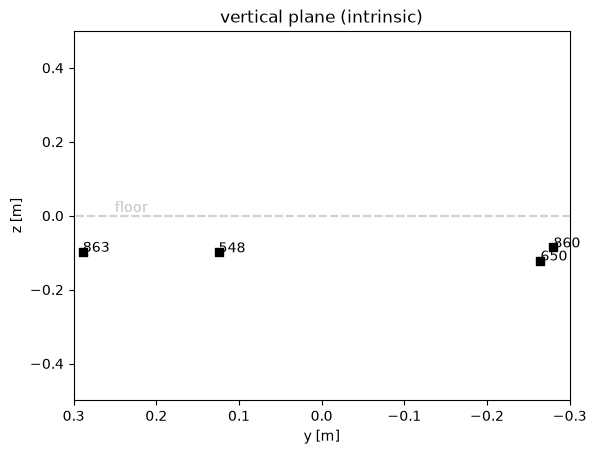

In [64]:
plt.figure()
for i, c in enumerate(marker_tvecs_robot):
    id = ids[i]
    plt.scatter([c[1]], [c[2]], color="black", marker="s")
    plt.text(c[1], c[2], str(id))
    plt.ylabel("z [m]")
    plt.xlabel("y [m]")
    plt.xlim([-0.3, 0.3])
    plt.ylim([-0.5, 0.5])
    plt.axhline(0,-1,1, color="lightgray", ls="--")
    plt.text(0.25, 0.01, "floor", color="lightgray")

plt.gca().invert_xaxis()
plt.title("vertical plane (intrinsic)")
plt.show()

We can see that, although all markers in the image are obviously placed directly on the floor, our estimated positions don't line up perfectly with it. Some markers are estimated to "float" a bit above the floor, some are estimated to be slightly below it. This kind of imperfect measurement is something we must always expect when working with imperfect data. In our example, our camera calibration might not be completely optimal or our images might be noisy, etc. Overall, however, these results aren't too bad and definitely still usable for our purposes.

Next, we visualise where the markers are on the horizontal plane (i.e. the floor), relative to our robot. Because the robot is the reference point, it will always be at position (0,0).

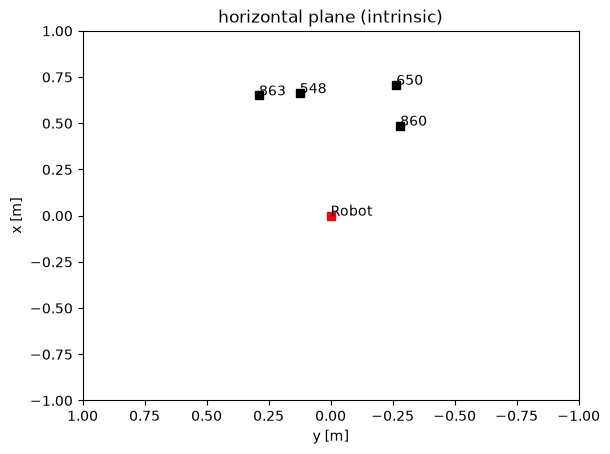

In [65]:
plt.figure()
for i, c in enumerate(marker_tvecs_robot):
    id = ids[i]
    plt.scatter([c[1]], [c[0]], color="black", marker="s")
    plt.text(c[1], c[0], str(id))
    plt.ylabel("x [m]")
    plt.xlabel("y [m]")
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.scatter([0], [0], color="red", marker="s")
plt.text(0, 0, "Robot")
plt.gca().invert_xaxis()
plt.title("horizontal plane (intrinsic)")
plt.show()

### Projecting to world frame (intrinsic)

Now that we know where the markers are relative to our robot, we want to determine where they are in our world coordinate frame. We will later need this to, for example, implement the landmark detection and localisation, as well as the SLAM algorithm for our robot.

Let's assume that our robot started at the origin of the world coordinate frame. Now it has moved 40cm forwards and 25cm to the left, with a current heading of 30° to the right.

In [66]:
# offset from robot to world frame (meters)
x_offset_world = 0.4
y_offset_world = 0.25
z_offset_world = 0

# angle from robot to world frame (degrees)
x_angle_world = 0
y_angle_world = 0
z_angle_world = -30

offset_robot_world = np.array([x_offset_world, y_offset_world, z_offset_world])
rotation_robot_world = np.array([np.radians(x_angle_world),
                                 np.radians(y_angle_world),
                                 np.radians(z_angle_world)])

**Task:** Create the transform matrix from the robot frame to the world frame. Store the result in *T_robot_world*.

In [70]:
### Your code here ###
# transformation matrix from the robot frame to the world frame
T_robot_world = vectors_to_transformation_matrix(rotation_robot_world,offset_robot_world)
###

print(T_robot_world)

[[ 0.8660254  0.5        0.         0.4      ]
 [-0.5        0.8660254 -0.         0.25     ]
 [-0.         0.         1.         0.       ]
 [ 0.         0.         0.         1.       ]]


**Task:** Create transform matrices for all markers in the robot coordinate frame, project them into the world coordinate frame, and transform them to rotation and translation vectors. Also print the id and world position for each marker.

In [75]:
marker_rvecs_world = []
marker_tvecs_world = []

### Your code here ###
# for each marker: build its marker->robot transform, chain it with the
# robot->world transform, and convert the result back into rotation and
# translation vectors (append to marker_rvecs_world / marker_tvecs_world)
for rvec, tvec in zip(marker_rvecs_robot, marker_tvecs_robot):

    R_marker_camera, _ = cv2.Rodrigues(rvec)
    T_marker_camera = np.eye(4)
    T_marker_camera[:3, :3] = R_marker_camera
    T_marker_camera[:3, 3] = tvec.ravel()

    T_marker_robot = np.dot(T_robot_world,T_marker_camera)

    rvec_robot, _ = cv2.Rodrigues(T_marker_robot[:3, :3])
    tvec_robot = T_marker_robot[:3, 3]

    marker_rvecs_world.append(rvec_robot.ravel())
    marker_tvecs_world.append(tvec_robot)

###

for i in range(len(ids)):
    print(f"Marker {ids[i]}: world position (x, y, z) = ({marker_tvecs_world[i][0]:.3f}, {marker_tvecs_world[i][1]:.3f}, {marker_tvecs_world[i][2]:.3f}) m")

Marker 548: world position (x, y, z) = (1.036, 0.026, -0.099) m
Marker 863: world position (x, y, z) = (1.108, 0.175, -0.098) m
Marker 860: world position (x, y, z) = (0.682, -0.236, -0.086) m
Marker 650: world position (x, y, z) = (0.881, -0.333, -0.121) m


Let's now again visualise our results. First, we plot where our markers are relative to the floor.

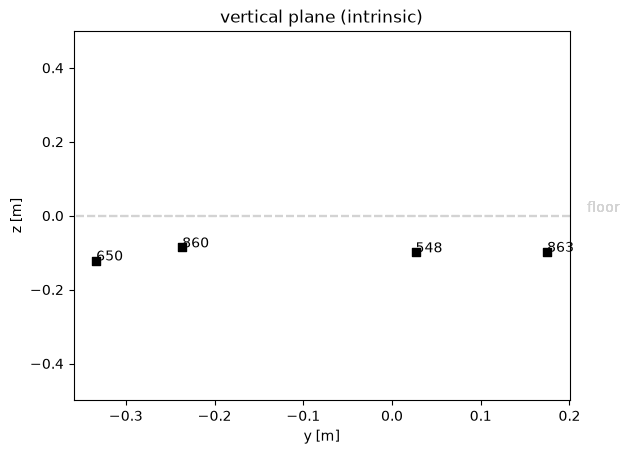

In [76]:
plt.figure()
for i, c in enumerate(marker_tvecs_world):
    id = ids[i]
    plt.scatter([c[1]], [c[2]], color="black", marker="s")
    plt.text(c[1], c[2], str(id))
    plt.ylabel("z [m]")
    plt.xlabel("y [m]")
    plt.ylim([-0.5, 0.5])
    plt.axhline(0,-1,1, color="lightgray", ls="--")
    plt.text(0.22, 0.01, "floor", color="lightgray")
plt.title("vertical plane (intrinsic)")
plt.show()

The measurement error from the previous pose estimation step obviously still exists, but overall our measurement is still good enough to use it, for example for navigation.

Finally, we again visualise the positions of the markers in the horizontal plane. This time we also visualise the position of our robot. This gives us essentially a section of our world map.

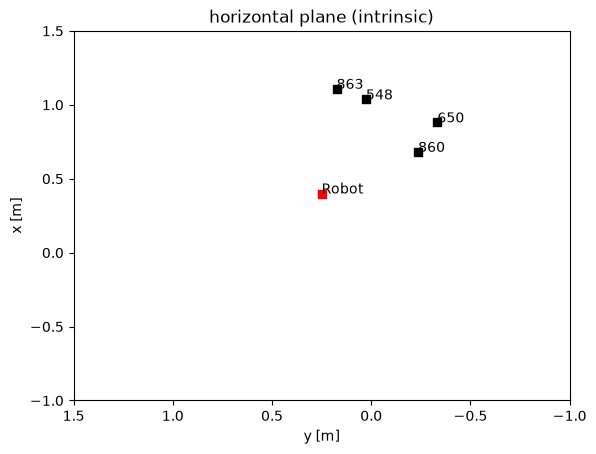

In [77]:
plt.figure()
for i, c in enumerate(marker_tvecs_world):
    id = ids[i]
    plt.scatter([c[1]], [c[0]], color="black", marker="s")
    plt.text(c[1], c[0], str(id))
    plt.ylabel("x [m]")
    plt.xlabel("y [m]")
plt.xlim(-1, 1.5)
plt.ylim(-1, 1.5)
plt.gca().invert_xaxis()
plt.scatter([y_offset_world], [x_offset_world], color="red", marker="s")
plt.text(y_offset_world, x_offset_world, "Robot")
plt.title("horizontal plane (intrinsic)")
plt.show()

## Extrinsic Rotations

So far, all rotations were **intrinsic**: we rotated about the (moving) body axes, in the order z -> y -> x.

There is a second, equally common convention: **extrinsic** rotations, where we rotate about the **fixed** (world) axes. For the same angle sequence z -> y -> x applied about the *fixed* axes, the rotation matrix is the reversed product:

```
    R_extrinsic = Rx(gamma) * Ry(beta) * Rz(alpha)
```

Crucially, intrinsic and extrinsic are just two **ways of parameterising the same physical rotation**. A given orientation has one unique rotation matrix, and both conventions describe that same matrix using a (different) set of euler angles. This means a correctly implemented extrinsic pipeline must reconstruct the *same* marker positions relative to the robot as the intrinsic one.

What we must NOT do is blindly feed the intrinsic angle triple into the extrinsic formula -- that would describe a different orientation. Instead, we take the true rotation matrix (already known from the intrinsic section) and re-express it in the extrinsic convention:

In [78]:
def extrinsic_rotation_matrix(x_rotation, y_rotation, z_rotation):
    """Rotation matrix for an EXTRINSIC z-y-x rotation.

    Rotates about the fixed (world) axes in the order z, then y, then x, which
    is equivalent to R = Rx(gamma) * Ry(beta) * Rz(alpha).
    """
    alpha = z_rotation
    beta = y_rotation
    gamma = x_rotation

    Rz = np.array([[np.cos(alpha), -np.sin(alpha), 0],
                   [np.sin(alpha),  np.cos(alpha), 0],
                   [0, 0, 1]])
    Ry = np.array([[np.cos(beta), 0, np.sin(beta)],
                   [0, 1, 0],
                   [-np.sin(beta), 0, np.cos(beta)]])
    Rx = np.array([[1, 0, 0],
                   [0, np.cos(gamma), -np.sin(gamma)],
                   [0, np.sin(gamma),  np.cos(gamma)]])

    return Rx @ Ry @ Rz

**Task:** Provide extrinsic versions of the two helpers from above.

In [ ]:
def vectors_to_transformation_matrix_ext(rotation, translation):
    ### Your code here ###
    x,y,z=rotation
    R_matrix=extrinsic_rotation_matrix(x,y,z)
    
        # create a 4x4 identity matrix and fill in the rotation and translation
    T = np.eye(4)
    T[:3, :3] = R_matrix
    T[:3, 3] = translation
    ###
    return T

def transformation_matrix_to_vectors_ext(t):
    ### Your code here ###
    R = t[:3, :3]
    translation = t[:3, 3]
    # recover the z-y-x intrinsic euler angles from the rotation matrix
    x_rotation = np.arctan2(-R[1, 2], R[2, 2])
    y_rotation = np.arctan2(R[0, 2], np.sqrt(R[0, 0]**2 + R[0, 1]**2))
    z_rotation = np.arctan2(-R[0, 1], R[0, 0])
    ###
    return np.array([x_rotation, y_rotation, z_rotation]), translation

### Projecting to robot frame (extrinsic)

We obtain the extrinsic angles from the very same physical rotation matrix that we already established with the intrinsic convention.

In [82]:
# To describe the SAME physical camera->robot rotation with the extrinsic convention,
# extract the extrinsic z-y-x euler angles from the true rotation matrix T_camera_robot
# (rather than reusing the intrinsic angles directly in the extrinsic formula).
rotation_camera_robot_ext = transformation_matrix_to_vectors_ext(T_camera_robot)[0]
print("extrinsic euler angles (x, y, z) [rad]:", np.round(rotation_camera_robot_ext, 4))

# build the extrinsic transform from these angles -> identical physical transform
T_camera_robot_ext = vectors_to_transformation_matrix_ext(rotation_camera_robot_ext, offset_camera_robot)
print("\nT_camera_robot_ext:\n", T_camera_robot_ext)

extrinsic euler angles (x, y, z) [rad]: [-2.4435  0.     -1.5708]

T_camera_robot_ext:
 [[ 6.12323400e-17  1.00000000e+00  0.00000000e+00  3.00000000e-02]
 [ 7.66044443e-01 -4.69066938e-17  6.42787610e-01  0.00000000e+00]
 [ 6.42787610e-01 -3.93593894e-17 -7.66044443e-01  2.80000000e-01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


**Task:** Project all markers into the robot coordinate frame using extrinsic rotations.

In [88]:
marker_rvecs_robot_ext = []
marker_tvecs_robot_ext = []

### Your code here ###
# same idea as the intrinsic robot-frame projection, but using the
# extrinsic conventions (T_camera_robot_ext, transformation_matrix_to_vectors_ext)

for rvec, tvec in zip(marker_rvecs, marker_tvecs):

    R_marker_camera, _ = cv2.Rodrigues(rvec)
    T_marker_camera = np.eye(4)
    T_marker_camera[:3, :3] = R_marker_camera
    T_marker_camera[:3, 3] = tvec.ravel()

    T_marker_robot = np.dot(T_camera_robot_ext,T_marker_camera)

    rvec_robot,tvec_robot=transformation_matrix_to_vectors_ext(T_marker_robot)

    marker_rvecs_robot_ext.append(rvec_robot.ravel())
    marker_tvecs_robot_ext.append(tvec_robot)
###
###

for i in range(len(ids)):
    print(f"Marker {ids[i]}: position (x, y, z) = ({marker_tvecs_robot_ext[i][0]:.3f}, {marker_tvecs_robot_ext[i][1]:.3f}, {marker_tvecs_robot_ext[i][2]:.3f}) m")

Marker 548: position (x, y, z) = (-0.211, 0.353, -0.334) m
Marker 863: position (x, y, z) = (-0.203, 0.221, -0.433) m
Marker 860: position (x, y, z) = (-0.085, 0.584, 0.021) m
Marker 650: position (x, y, z) = (-0.232, 0.681, -0.119) m


Visualise the extrinsic results on the vertical and horizontal planes.

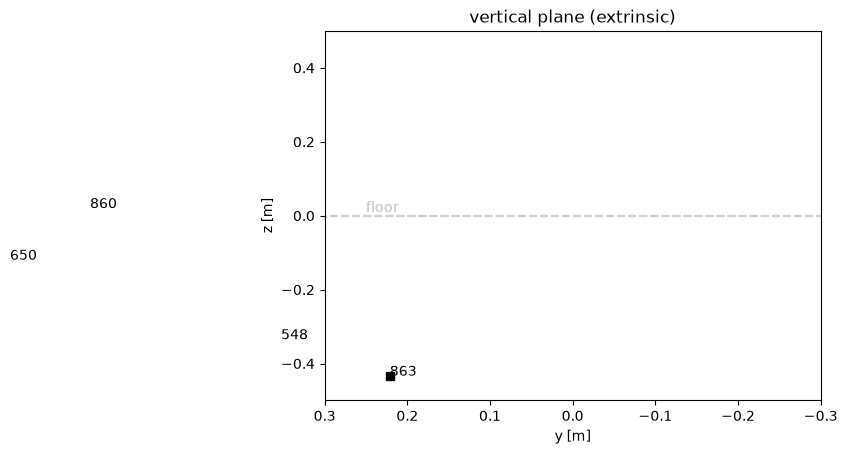

In [89]:
plt.figure()
for i, c in enumerate(marker_tvecs_robot_ext):
    id = ids[i]
    plt.scatter([c[1]], [c[2]], color="black", marker="s")
    plt.text(c[1], c[2], str(id))
    plt.ylabel("z [m]")
    plt.xlabel("y [m]")
    plt.xlim([-0.3, 0.3])
    plt.ylim([-0.5, 0.5])
    plt.axhline(0,-1,1, color="lightgray", ls="--")
    plt.text(0.25, 0.01, "floor", color="lightgray")

plt.gca().invert_xaxis()
plt.title("vertical plane (extrinsic)")
plt.show()

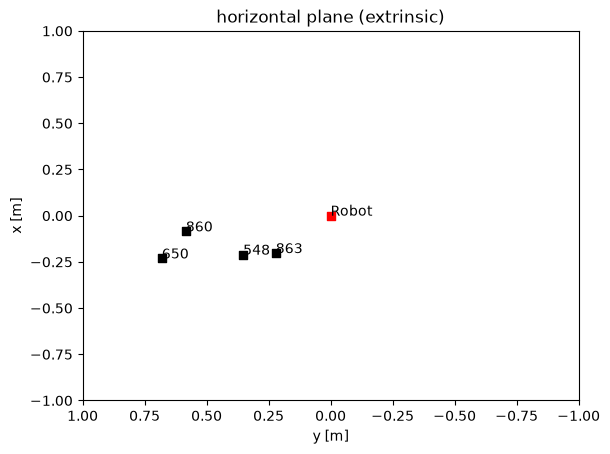

In [86]:
plt.figure()
for i, c in enumerate(marker_tvecs_robot_ext):
    id = ids[i]
    plt.scatter([c[1]], [c[0]], color="black", marker="s")
    plt.text(c[1], c[0], str(id))
    plt.ylabel("x [m]")
    plt.xlabel("y [m]")
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.scatter([0], [0], color="red", marker="s")
plt.text(0, 0, "Robot")
plt.gca().invert_xaxis()
plt.title("horizontal plane (extrinsic)")
plt.show()

### Projecting to world frame (extrinsic)

The robot->world rotation is a pure rotation about z, for which the intrinsic and extrinsic conventions coincide. For consistency we still re-express it with the extrinsic convention.

In [ ]:
# pure z rotation -> intrinsic and extrinsic coincide; re-express extrinsically anyway
rotation_robot_world_ext = transformation_matrix_to_vectors_ext(T_robot_world)[0]
T_robot_world_ext = vectors_to_transformation_matrix_ext(rotation_robot_world_ext, offset_robot_world)
print(T_robot_world_ext)

**Task:** Project all markers into the world coordinate frame using extrinsic rotations.

In [ ]:
marker_rvecs_world_ext = []
marker_tvecs_world_ext = []

### Your code here ###
# same idea as the intrinsic world-frame projection, but using the
# extrinsic conventions (T_robot_world_ext, transformation_matrix_to_vectors_ext)


###

for i in range(len(ids)):
    print(f"Marker {ids[i]}: world position (x, y, z) = ({marker_tvecs_world_ext[i][0]:.3f}, {marker_tvecs_world_ext[i][1]:.3f}, {marker_tvecs_world_ext[i][2]:.3f}) m")

Visualise the extrinsic world-frame results.

In [ ]:
plt.figure()
for i, c in enumerate(marker_tvecs_world_ext):
    id = ids[i]
    plt.scatter([c[1]], [c[2]], color="black", marker="s")
    plt.text(c[1], c[2], str(id))
    plt.ylabel("z [m]")
    plt.xlabel("y [m]")
    plt.ylim([-0.5, 0.5])
    plt.axhline(0,-1,1, color="lightgray", ls="--")
    plt.text(0.22, 0.01, "floor", color="lightgray")
plt.title("vertical plane (extrinsic)")
plt.show()

In [ ]:
plt.figure()
for i, c in enumerate(marker_tvecs_world_ext):
    id = ids[i]
    plt.scatter([c[1]], [c[0]], color="black", marker="s")
    plt.text(c[1], c[0], str(id))
    plt.ylabel("x [m]")
    plt.xlabel("y [m]")
plt.xlim(-1, 1.5)
plt.ylim(-1, 1.5)
plt.gca().invert_xaxis()
plt.scatter([y_offset_world], [x_offset_world], color="red", marker="s")
plt.text(y_offset_world, x_offset_world, "Robot")
plt.title("horizontal plane (extrinsic)")
plt.show()

### Intrinsic vs. extrinsic

Intrinsic and extrinsic rotations are two equivalent ways to parameterise the same physical rotation - they differ only in the euler-angle triple used to describe it, not in the resulting orientation. As long as we re-express the true rotation matrix in the matching convention, both pipelines reconstruct the *same* marker positions.

A convenient intuition: because the robot->world rotation is a pure rotation about z, its intrinsic and extrinsic euler triples coincide. The camera->robot rotation, in contrast, involves both x and z, so its extrinsic triple (about -180 deg, 40 deg, 90 deg) looks very different from the intrinsic one (-140 deg, 0 deg, -90 deg) -- yet both describe the identical orientation.

We verify the equivalence by comparing the marker positions in the robot frame computed with both conventions:

In [ ]:
print("Marker positions in the robot frame (x, y, z) [m] - intrinsic vs extrinsic:")
print(f"{'id':>4} {'intrinsic':>30} {'extrinsic':>30} {'|diff|':>12}")
for i in range(len(ids)):
    pi = marker_tvecs_robot[i]
    pe = marker_tvecs_robot_ext[i]
    print(f"{ids[i]:>4} {np.round(pi,3)} {np.round(pe,3)} {np.linalg.norm(pi - pe):12.3e}")

print("\nThe intrinsic and extrinsic pipelines agree to floating-point precision,")
print("because they describe the very same physical rotations.")